In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspaces\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


In [49]:
import os
import time
import pickle
import base64
import tiktoken
import uuid
import re
from pathlib import Path
from dotenv import load_dotenv
from openai import OpenAI, AuthenticationError
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import HumanMessage
from langchain_core.documents import Document as _Doc
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_core.stores import InMemoryStore
from langchain_text_splitters import CharacterTextSplitter
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
from langchain_openai import ChatOpenAI
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
from unstructured.partition.pdf import partition_pdf
from collections import Counter
from IPython.display import Image, display

print("임포트 완료")

임포트 완료


In [ ]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

fname = "invest.pdf"
pdf_dir = Path("../data")
pdf_path = pdf_dir / fname

fpath = str(pdf_dir) + os.sep

print("현재 위치 : " , Path.cwd())
print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 폴더     :", pdf_dir, pdf_path.resolve())
print("PDF 존재 여부:", pdf_path.exists())

현재 위치 :  c:\workspaces\multimodal-rag\notebooks
프로젝트 루트: c:\workspaces\multimodal-rag
PDF 폴더     : ..\data C:\workspaces\multimodal-rag\data\invest.pdf
PDF 존재 여부: True


In [23]:
load_dotenv(PROJECT_ROOT / ".env")

try:
    openai_api_key = os.environ["OPENAI_API_KEY"]
    if not openai_api_key.strip():
        raise ValueError("OPENAI_API_KEY 값이 비어 있습니다. .env 파일을 확인하세요.")
    else:
        print("환경변수 OPENAI_API_KEY 로드 완료")
except KeyError:
    raise ValueError("환경변수 OPENAI_API_KEY 키가 없습니다. .env 파일을 확인하세요.")

환경변수 OPENAI_API_KEY 로드 완료


In [25]:
try:
    OpenAI(api_key=openai_api_key).models.list()
    print("Good")
except AuthenticationError:
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")

Good


In [10]:
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.

    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",
        extract_images_in_pdf=True,
        infer_table_structure=True,
        chunking_strategy="by_title",
        max_characters=4000,
        new_after_n_chars=3800,
        combine_text_under_n_chars=2000,
        extract_image_block_output_dir=path+"figures",
    )


print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


In [11]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))

    return texts, tables


print("categorize_elements 정의 완료")

categorize_elements 정의 완료


In [12]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 2357.76it/s]


추출 완료 — 172.2초 소요
추출된 전체 요소 수: 14


In [13]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

텍스트 블록 수: 10
표 블록 수    : 4


In [14]:
counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 10개
Table                 : 4개


In [15]:
figures_dir = Path(fpath) / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("X figures 폴더가 없습니다.")

추출된 이미지: 27개

  figure-1-1.jpg  (13 KB)
  figure-1-2.jpg  (7 KB)
  figure-1-3.jpg  (15 KB)
  figure-10-15.jpg  (59 KB)
  figure-10-16.jpg  (211 KB)
  figure-11-17.jpg  (36 KB)
  figure-11-18.jpg  (93 KB)
  figure-12-19.jpg  (91 KB)
  figure-12-20.jpg  (83 KB)
  figure-12-21.jpg  (182 KB)


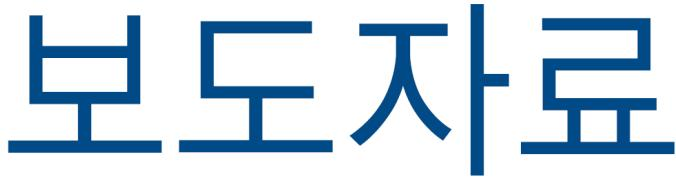

In [16]:
if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

In [17]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 10
분할 후 블록 수: 6
전체 글자 수  : 19507


In [20]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
H 2026-10-172 4 22a 4 [oe] a4 —I 202614 10

HOE

BHA EY FOO] FUAlO. 0] ARE

7}(202644 102)

Zot CHO BEA G72 SI =A | — ir Seas mun

At —_ <0 <i Cheol] Chet ee +e A i =} =

—_, 00 <0 m4

7}(202644 10#) 42 ast y > BH O im} = — LWBe2 < —_ or x XA

(4172) A (4190) El At (4205) {2} cu |S? (4167), & % x| 1

[분할 texts_2k_token[0]] 앞 300자
H 2026-10-172 4 22a 4 [oe] a4 —I 202614 10

HOE

BHA EY FOO] FUAlO. 0] ARE

7}(202644 102)

Zot CHO BEA G72 SI =A | — ir Seas mun

At —_ <0 <i Cheol] Chet ee +e A i =} =

—_, 00 <0 m4

7}(202644 10#) 42 ast y > BH O im} = — LWBe2 < —_ or x XA

(4172) A (4190) El At (4205) {2} cu |S? (4167), & % x| 1


In [27]:
def generate_text_summaries(texts, tables, summarize_texts=False):
    prompt_text = """표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 / 
                        검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"""
    prompt = ChatPromptTemplate.from_template(prompt_text)
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

    text_summaries = []
    table_summaries = []
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts:
        text_summaries = texts

    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})

    return text_summaries, table_summaries

print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


In [28]:
start = time.time()

text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)

print(f"소요 시간: {time.time() - start:.1f}초")
print(f"텍스트 요약 수: {len(text_summaries)}")
print(f"표 요약 수: {len(table_summaries)}")

소요 시간: 15.8초
텍스트 요약 수: 6
표 요약 수: 4


In [29]:
print("="*60)
print("[원본]texts_2k_token[0] 의 앞 300자")
print("="*60)
print(texts_2k_token[0][:300])
print()
print("="*60)
print("[요약본]text_summaries[0] 전체")
print("="*60)
print(text_summaries[0])
print()
print(f"원본 글자 수: {len(texts_2k_token[0])}")
print(f"요약 글자 수: {len(text_summaries[0])}")
print(f"압축률(%): {(len(text_summaries[0])/len(texts_2k_token[0]))*100}%")

[원본]texts_2k_token[0] 의 앞 300자
H 2026-10-172 4 22a 4 [oe] a4 —I 202614 10

HOE

BHA EY FOO] FUAlO. 0] ARE

7}(202644 102)

Zot CHO BEA G72 SI =A | — ir Seas mun

At —_ <0 <i Cheol] Chet ee +e A i =} =

—_, 00 <0 m4

7}(202644 10#) 42 ast y > BH O im} = — LWBe2 < —_ or x XA

(4172) A (4190) El At (4205) {2} cu |S? (4167), & % x| 1

[요약본]text_summaries[0] 전체
**요약:**

- **주요 데이터**: 
  - 날짜: 2026-10-17
  - 관련 기관: 한국은행 (Bank of Korea)
  - 전화번호: 02-759-4202, 02-759-4016

- **경제 지표**:
  - PMI (구매관리자지수): 300, 250, 200, 100 등 다양한 수치가 언급됨.
  - S&P Global 및 Bloomberg 데이터 참조.

- **기타 정보**:
  - 다양한 경제 지표와 통계가 포함되어 있으며, 특정 수치와 비율이 강조됨.
  - 한국은행의 정책 및 경제 전망에 대한 언급이 포함됨.

이 요약은 검색 최적화를 위해 간결하게 작성되었습니다.

원본 글자 수: 3698
요약 글자 수: 336
압축률(%): 9.085992428339642%


In [30]:
if table_summaries:
    for i, (table, summary) in enumerate(zip(tables[:3], table_summaries[:3])):
        print("="*60)
        print(f"[원본 {i+1} (앞 300자)]")
        print("="*60)
        print(table[:300])
        print()
        print("="*60)
        print(f"[요약본 {i+1}]")
        print("="*60)
        print(summary)
        print()
else:
    print("표 요약이 비어 있습니다.")

[원본 1 (앞 300자)]
(A7|CHH], %) 2024 ase AZ 4/4 | 1/4 2/4 GDPAes” 30} 23 O2] 25 22 . - - - At ey a8 At?) 0.7) 11 -05) O38 12 #07 #402 #01 £407 Oo] 2. o4=to} 15; 32 O06] O8 28 12 -04 #13 £4008 = AW|xHE Ip) 29) 26 27| 27 #39 35 34 34 37 saine, t 1826] 764 -91| 130 291 130 -10 133 29 GDPAtsS 13} 12 #02} 00 06 . - - - Ate

[요약본 1]
요약: 

- 데이터는 여러 지표와 수치를 포함하고 있으며, 특정 값들이 나열되어 있음.
- 주요 지표: GDPAes, AES, NOH, DAE 등.
- 수치 범위: 0.1에서 61까지 다양하며, 일부 값은 음수로 나타남.
- 특정 항목들은 반복적으로 나타나며, 여러 카테고리에서 수치가 기록됨.
- 전반적으로 데이터는 경제적 지표와 관련된 것으로 보임. 

이 요약은 검색 최적화를 위해 간결하게 작성되었습니다.

[원본 2 (앞 300자)]
92 102? 114 108 78 97 «91 84 BBS«102 104 75 81 Dubai?” Brent?” OH AAA?

[요약본 2]
주어진 데이터를 검색에 최적화된 간결한 요약으로 변환하면 다음과 같습니다:

**요약:** 숫자 목록: 92, 102, 114, 108, 78, 97, 91, 84, 102, 104, 75, 81. 질문: "Dubai?" "Brent?" "OH AAA?" 

이 요약은 원본 데이터를 간결하게 정리하여 검색 시 필요한 정보를 쉽게 찾을 수 있도록 돕습니다.

[원본 3 (앞 300자)]
07 0x GDP As 2.2 1.1 -0.1 1.8 0.6 - - - 2S OY EO} OF -19 0.3 0.6 24 -18 26 -18 (S'S 7| Chl) (0.9) | (3.2) (2.3) (-1.0) (-0.3) JH

In [32]:
def encode_image(image_path):
    with open(image_path, "rb") as img_file:
        return base64.b64encode(img_file.read()).decode("UTF-8")

img_files = sorted( # 3. 이름순으로 정렬해서 리스트로 반환하겠다.
    f for f in figures_dir.iterdir() # 1. 폴더 안의 항목들을 하나씩 꺼내
    if f.suffix.lower() in (".jpg", ".jpeg", ".png") # 2. 확장자가 이미지인 것만
)
sample_b64 = encode_image(img_files[0])

print(f"원본 파일: {img_files[0].name}")
print(f"문자열 길이: {len(sample_b64)}자")
print(f"앞 100자: {sample_b64[:100]}")

원본 파일: figure-1-1.jpg
문자열 길이: 18696자
앞 100자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


In [ ]:
def image_summarize(img_base64, prompt):
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)
    msg = chat.invoke([
        HumanMessage(content=[
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/jpg;base64,{img_base64}"},
             },
        ])
    ])

    return msg.content

test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

print(image_summarize(sample_b64, test_prompt))

"보도자료"라는 단어가 파란색으로 적힌 이미지.


In [34]:
def generate_img_summaries(path):
    img_base64_list = []
    img_summaries = []
    prompt_kor = """당신은 검색을 위해 이미지를 요약하는 어시스턴트입니다.
    이 요약문은 임베딩되어 원본 이미지를 검색하는 데 사용됩니다.
    검색에 최적화된 간결한 이미지 요약을 작성하세요."""

    for img_file in sorted(os.listdir(path)):
        if img_file.endswith((".jpg", ".jpeg", ".png")):
            img_path = os.path.join(path, img_file)
            b64_img = encode_image(img_path)
            img_base64_list.append(b64_img)
            img_summaries.append(image_summarize(b64_img, prompt_kor))

    return img_base64_list, img_summaries

print("이미지 요약 정의 완료")

이미지 요약 정의 완료


In [35]:
start = time.time()

img_base64_list, img_summaries = generate_img_summaries(str(figures_dir))

print(f"소요 시간: {time.time() - start:.1f}초")
print(f"요약된 이미지 수: {len(img_summaries)}")

소요 시간: 285.0초
요약된 이미지 수: 27


[1] figure-1-1.jpg


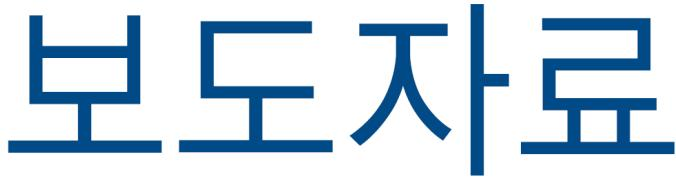

요약: 이 이미지는 "보도자료"라는 한국어 텍스트가 포함되어 있습니다. "보도자료"는 일반적으로 언론에 배포되는 공식적인 문서로, 사건이나 발표에 대한 정보를 제공합니다. 추가적인 도움이 필요하시면 말씀해 주세요!

[2] figure-1-2.jpg


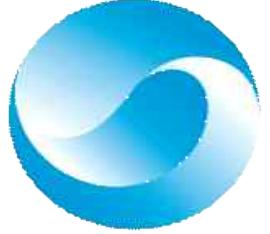

요약: 해당 이미지는 파란색 원 안에 물결 모양의 형상이 포함된 로고입니다. 더 궁금한 점이나 필요한 정보가 있다면 말씀해 주세요!

[3] figure-1-3.jpg


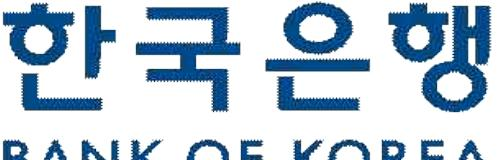

요약: 이미지에 대한 설명: 이 이미지는 "한국은행"과 "BANK OF KOREA"라는 문구가 포함된 로고입니다. 텍스트는 진한 파란색으로 되어 있으며, 한국 은행의 공식 로고인 것 같습니다.

[4] figure-10-15.jpg


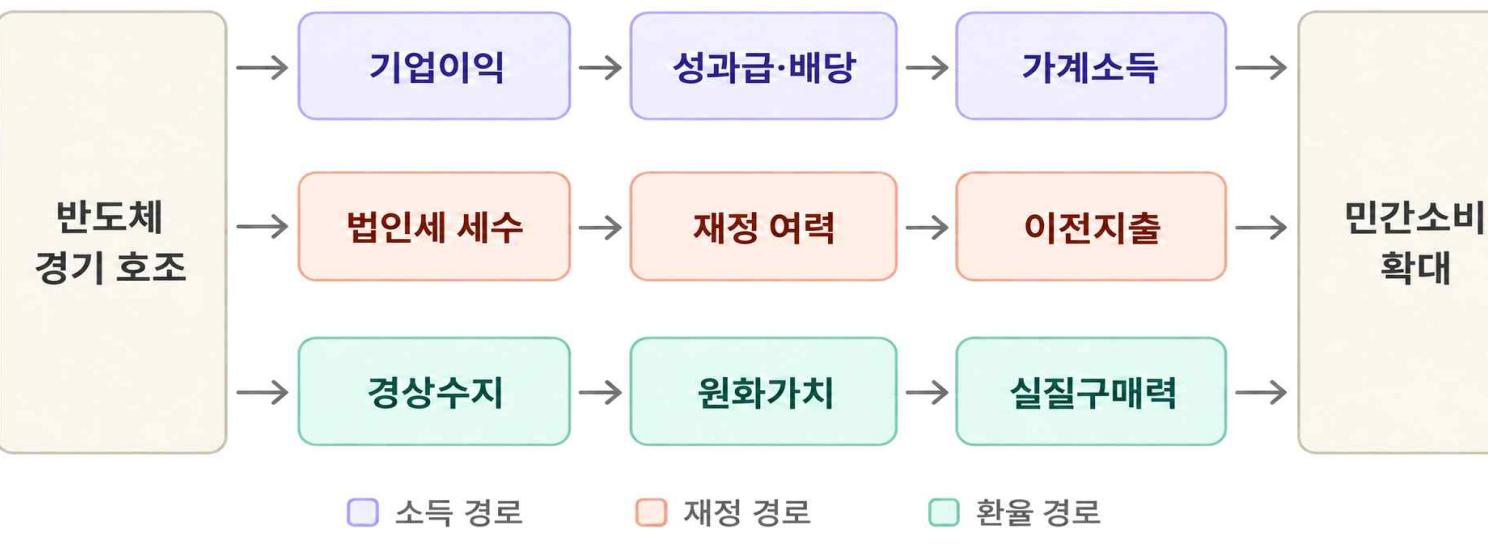

요약: 이 이미지는 "반도체 경기 호조"와 관련된 흐름을 나타내고 있습니다. 다음은 각 항목의 설명입니다:

1. **기업의익**: 반도체 산업의 기업들이 얻는 이익.
2. **성과급·배당**: 기업의 성과에 따라 지급되는 보상 및 배당금.
3. **가계소득**: 개인 혹은 가계의 총 수입.
4. **법인세 세수**: 정부의 법인세로부터의 세입.
5. **재정역력**: 정부의 재정적 능력.
6. **이전지출**: 정부가 사회 복지 등을 위해 지급하는 금액.
7. **경상수지**: 국가의 수출입 차이.
8. **원화가치**: 원화의 상대적인 가치.
9. **실질구매력**: 실제 소비자가 구매할 수 있는 능력.
10. **민간소비 확대**: 민간 부문의 소비 증가.

이 흐름은 반도체 산업이 긍정적인 영향을 미쳐 경제 전반에 걸쳐 소비와 소득을 증가시키는 과정을 설명하고 있습니다.

[5] figure-10-16.jpg


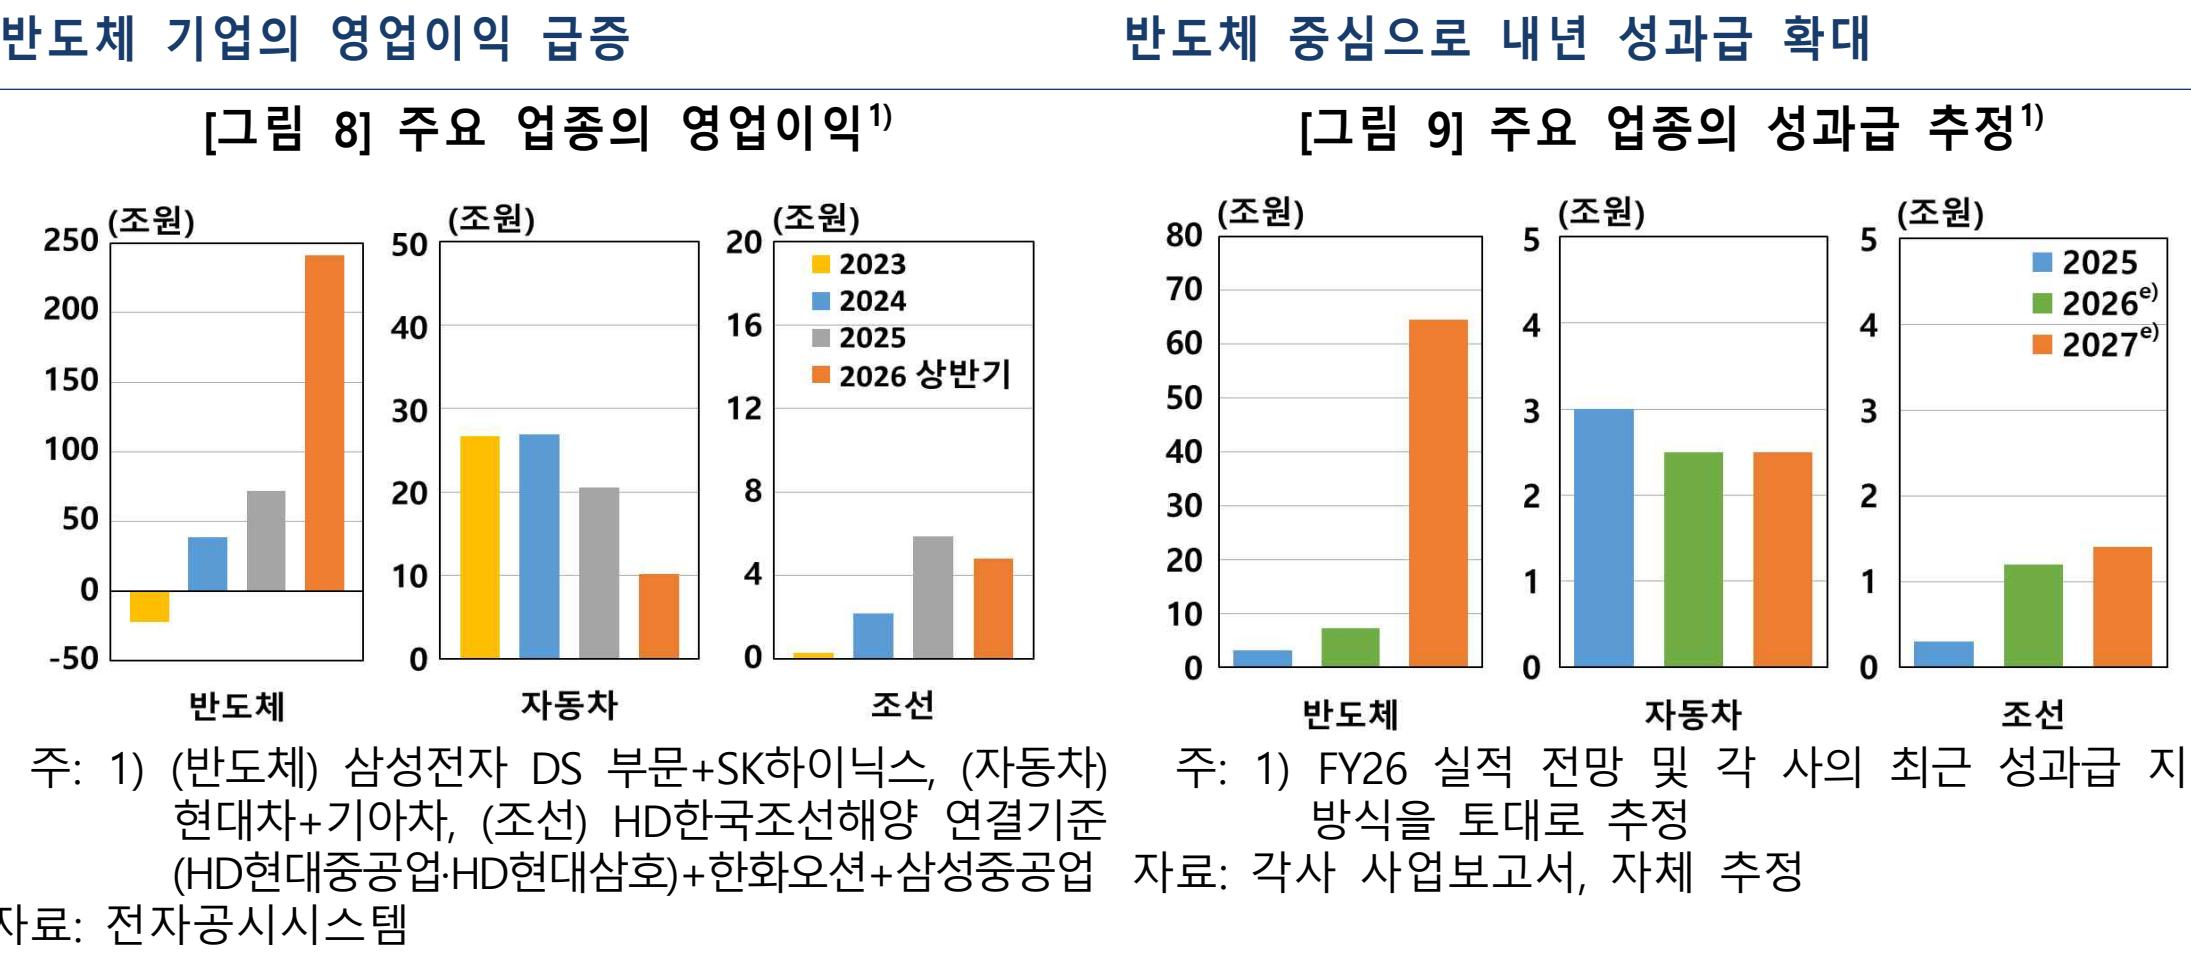

요약: 위의 그래프들은 반도체 산업 및 주요 업종의 영업이익과 향후 성과를 보여주고 있습니다. 

### [그림 8] 주요 업종의 영업이익
- 이 그래프는 반도체와 자동차, 조선 업종의 영업이익을 나타냅니다.
- 반도체 업종의 영업이익이 2023년부터 2026년 상반기까지 급증할 것으로 예측되고 있습니다.
- 자동차 업종은 각 연도별로 안정적인 성장을 보이는 한편, 조선 업종은 상대적으로 낮은 영업이익을 보이고 있습니다.

### [그림 9] 주요 업종의 성과급 추정
- 이 그래프는 2025년부터 2027년까지의 성과급 추정을 나타내고 있습니다.
- 반도체 업종에서의 성과가 가장 두드러지며, 자동차와 조선 업종은 이에 비해 성과가 낮은 편입니다.

이 데이터는 향후 반도체 산업의 성장세를 강조하며, 자동차와 조선 업종도 지속적인 성장을 기대할 수 있음을 보여줍니다.



In [37]:
for i, (img_file, summary) in enumerate(zip(img_files[:5], img_summaries[:5])):
    print("="*60)
    print(f"[{i+1}] {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file), width=450))
    print(f"요약: {summary}")
    print()

In [40]:
enc = tiktoken.encoding_for_model("gpt-4o-mini")
input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("="*60)
print(f"입력: {input_tokens}")
print(f"출력: {output_tokens}")
print(f"합계 토큰(천 단위 콤마): {input_tokens+output_tokens:,} 토큰")
print()
print(f"요약한 이미지 수: {len(img_summaries)} 장")
print("="*60)
print()

입력: 10882
출력: 1355
합계 토큰(천 단위 콤마): 12,237 토큰

요약한 이미지 수: 27 장



In [42]:
vectorstore = Chroma(
    collection_name="multimodal_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small")
)
store = InMemoryStore()
id_key = "doc_id"
retriever = MultiVectorRetriever(vectorstore=vectorstore, docstore=store, id_key=id_key)

print("검색기 생성 완료")

검색기 생성 완료


In [45]:
def add_documents(retriever, doc_summaries, doc_contents):
    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]
    summary_docs = [
        _Doc(page_content=s, metadata={id_key: doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]

    vectorstore = retriever.vectorstore.add_documents(summary_docs)
    store = retriever.docstore.mset(list(zip(doc_ids, doc_contents)))

if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if img_summaries:
    add_documents(retriever, img_summaries, img_base64_list)

print("색인 완료")
print(len(vectorstore.get()["ids"]))

색인 완료
37


In [47]:
query = "그래프에 나타난 국제유가 및 경유 가격에 대해 설명해줘"
found = retriever.invoke(query)

print(f"검색된 원본 수: {len(found)}")

for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_img = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    # Base64에 쓰는 문자만 100개 이상 이어지고, 끝에 = 이 0~2개 붙은 문자열은 이미지다.
    kind = "이미지(Base64)" if is_img else "텍스트/표"
    print(f"[{i}] {kind} - 길이: {len(content):,}자")
    print("   ", content[:120].replace('\n', ' '), "...")
    print()

검색된 원본 수: 4
[0] 이미지(Base64) - 길이: 274,608자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[1] 이미지(Base64) - 길이: 320,976자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[2] 이미지(Base64) - 길이: 99,264자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[3] 이미지(Base64) - 길이: 307,636자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...



In [ ]:
def split_image_text_types(docs):
    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
    b64_img = []
    texts_out = []

    for doc in docs:
        content = doc.page_content if isinstance(doc, _Doc) else doc
        if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content):
            b64_img.append(content)
        else:
            texts_out.append(content)

    return {"images": b64_img, "texts": texts_out}

split_data = split_image_text_types(found)
print(f"이미지: {len(split_data['images'])}")
print(f"텍스트: {len(split_data['texts'])}")

이미지: 4
텍스트: 0


In [ ]:
def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []

    for img in data_dict["context"]["images"]:
        messages.append(
            {"type": "image_url",
             "image_url": {"url": f"data:image/jpg;base64,{img}"}}
        )
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": ("자료를 근거로 질문에 한국어로 답하세요.\n"
        "자료에 없는 내용은 모른다고 답하세요.\n\n"
        f"질문: {data_dict['question']}\n\n"
        f"참고 텍스트:\n {formatted_texts}")
    })

    return [HumanMessage(content=messages)]

model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

chain = ({"context": retriever | RunnableLambda(split_image_text_types),
          "question": RunnablePassthrough()}
          | RunnableLambda(img_prompt_func)
          | model
          | StrOutputParser()
)

print("최종 체인 조립 완료")

최종 체인 조립 완료


In [51]:
start = time.time()
answer = chain.invoke(query)

print(f"소요 시간: {time.time() - start:.1f}초\n")
print(f"질문: {query}")
print("="*60)
print(answer)

소요 시간: 12.5초

질문: 그래프에 나타난 국제유가 및 경유 가격에 대해 설명해줘
그래프에 나타난 국제유가 및 경유 가격은 두 가지 주요 지표로 나뉘어 있습니다. 왼쪽 그래프는 국제유가를 나타내며, 두바이유, 브렌트유, 그리고 국제경유 가격의 변화를 보여줍니다. 오른쪽 그래프는 경유 가격의 변화를 나타내고 있습니다.

전체적으로 국제유가는 일정한 변동성을 보이며, 특정 시점에서 급격한 상승과 하락을 경험한 것으로 보입니다. 특히, 국제유가는 2022년 초에 급등한 후, 이후에는 다소 안정세를 보이는 경향이 있습니다. 경유 가격 역시 국제유가와 유사한 패턴을 보이며, 유가의 변화에 따라 영향을 받는 것으로 나타납니다.

이러한 데이터는 국제유가와 경유 가격이 경제 전반에 미치는 영향을 이해하는 데 중요한 정보를 제공합니다.


In [52]:
textstore = Chroma(collection_name="text_only_rag", embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"))
textstore.add_texts(texts=texts_2k_token)
text_retriever = textstore.as_retriever(search_kwargs={"k": 4})
text_prompt = ChatPromptTemplate.from_template(
    "자료를 근거로 질문에 한국어로 답하세요.\n" \
    "자료에 없는 내용은 모른다고 답하세요.\n\n" \
    "참고 텍스트: {context}\n\n" \
    "질문: {question}"
)

text_chain = ({"context": text_retriever | RunnableLambda(lambda docs: "\n".join(d.page_content for d in docs)),
               "question": RunnablePassthrough()}
               | text_prompt | model | StrOutputParser())

print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


In [53]:
print("="*60)
print(f"질문: {query}")
print("="*60)
print("[BEFORE] 텍스트 전용 RAG")
before = text_chain.invoke(query)
print(before)
print()
print("="*60)
print("[AFTER] 멀티모달 RAG")
after = chain.invoke(query)
print(after)
print()

질문: 그래프에 나타난 국제유가 및 경유 가격에 대해 설명해줘
[BEFORE] 텍스트 전용 RAG
자료에 국제유가 및 경유 가격에 대한 내용이 포함되어 있지 않으므로, 이에 대한 설명은 할 수 없습니다.

[AFTER] 멀티모달 RAG
그래프에 나타난 국제유가 및 경유 가격은 두 가지 주요 지표를 보여줍니다. 왼쪽 그래프는 국제유가의 변동을 나타내며, 두바이유, 브렌트유, 그리고 국제경유 가격이 포함되어 있습니다. 오른쪽 그래프는 경유 가격의 변화를 보여줍니다.

전체적으로 국제유가는 특정 시점에서 급격한 상승과 하락을 반복하며, 경유 가격도 이에 따라 영향을 받는 모습을 보입니다. 특히, 국제유가는 특정 시점에 급등한 후 다시 안정세를 찾는 경향이 있습니다. 경유 가격 역시 국제유가의 변동에 따라 유사한 패턴을 보이며, 전반적으로 상승세를 유지하고 있습니다.

이러한 데이터는 국제유가와 경유 가격 간의 상관관계를 잘 보여주며, 에너지 시장의 변동성을 반영하고 있습니다.

